
# Lab 08 — Chapter 3: Running Random Simulations in NumPy

**Course:** A310 — Problem Solving Using Data  
**Textbook:** Data Science Bookcamp — Leonard Apeltsin

## Introduction

Chapter 3 teaches us how to use NumPy to simulate random events, estimate probabilities, and analyze results using histograms and confidence intervals.

These tools help us understand randomness and prepare us to solve the card game in Case Study 1.


## Part 1 — Random Simulations

### 1. What is Chapter 3 about? What is its main goal?

Chapter 3 teaches us how to **simulate random events using NumPy**. The goal is to estimate probabilities when calculating every possible outcome would be too difficult.

### 2. Why can we now read it and make sense of it?

Chapters 1 and 2 introduced probability, sample spaces, and visualizations. Chapter 3 builds on those concepts by adding random simulations.

### 3. Why do we simulate coin flips and die rolls?

Coin flips and die rolls are simple random events with known probabilities. They help us understand how simulations work and how results approach expected probabilities with more trials.

Result of rolling a die: 5
Percentage of heads: 50.50%


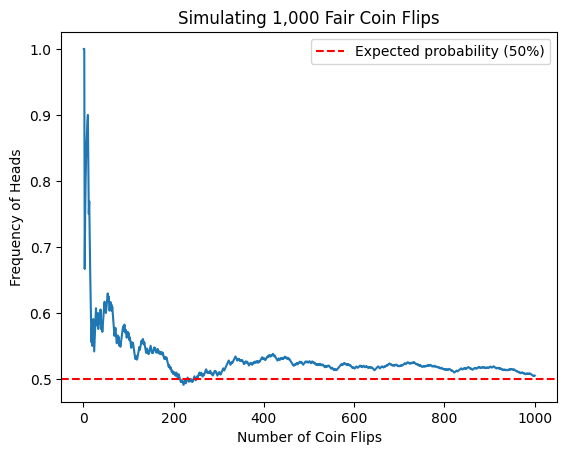

In [7]:

import numpy as np
import matplotlib.pyplot as plt

np.random.seed(0)

# Simulate rolling a six-sided die
die_roll = np.random.randint(1, 7)
print(f"Result of rolling a die: {die_roll}")

# Simulate 1,000 fair coin flips
coin_flips = np.random.randint(0, 2, 1000)

# Calculate the percentage of heads
heads_percentage = coin_flips.mean() * 100
print(f"Percentage of heads: {heads_percentage:.2f}%")

# Track the percentage of heads as we flip more coins
cumulative_heads = np.cumsum(coin_flips)
flip_counts = np.arange(1, 1001)
frequencies = cumulative_heads / flip_counts

plt.plot(flip_counts, frequencies)
plt.axhline(0.5, color="red", linestyle="--", label="Expected probability (50%)")
plt.xlabel("Number of Coin Flips")
plt.ylabel("Frequency of Heads")
plt.title("Simulating 1,000 Fair Coin Flips")
plt.legend()
plt.show()


**Observation:** The percentage of heads changes a lot at the beginning but becomes more stable as we flip more coins. This shows how random simulations get closer to the expected probability with more trials.

### 4. Why are we interested in biased coin flips?

Biased coins show us that not all outcomes are equally likely. This helps us understand situations where probabilities change, like the remaining red and black cards in our game.

Fair coin heads: 48.30%
Biased coin heads: 66.40%


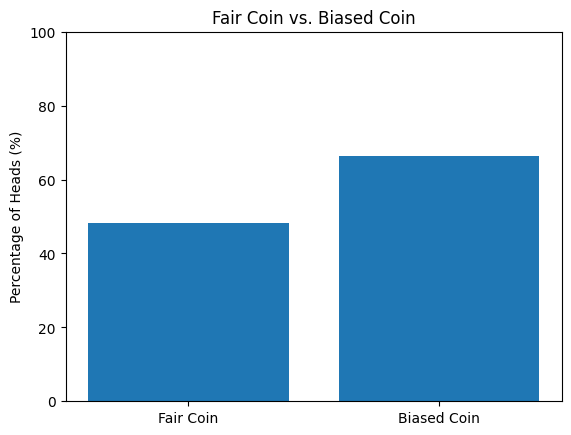

In [8]:

np.random.seed(0)

# Simulate 1,000 flips of a fair coin
fair_coin = np.random.binomial(1, 0.5, 1000)

# Simulate 1,000 flips of a biased coin
biased_coin = np.random.binomial(1, 0.7, 1000)

print(f"Fair coin heads: {fair_coin.mean() * 100:.2f}%")
print(f"Biased coin heads: {biased_coin.mean() * 100:.2f}%")

# Compare the results
labels = ["Fair Coin", "Biased Coin"]
percentages = [fair_coin.mean() * 100, biased_coin.mean() * 100]

plt.bar(labels, percentages)
plt.ylabel("Percentage of Heads (%)")
plt.title("Fair Coin vs. Biased Coin")
plt.ylim(0, 100)
plt.show()



**Observation:** The fair coin produces heads close to 50% of the time, while the biased coin produces heads close to 70%. This shows how different probabilities affect the results of a simulation.


## Part 2 — Understanding Simulation Results

### 5. What is a confidence interval and why is it important?

A **confidence interval** gives us a range for an estimate and helps describe its uncertainty. It tells us how reliable our simulation results are.

### 6. Why do we draw histograms?

Histograms show how often different results occur. They help us identify common outcomes, patterns, and the spread of our simulation data.

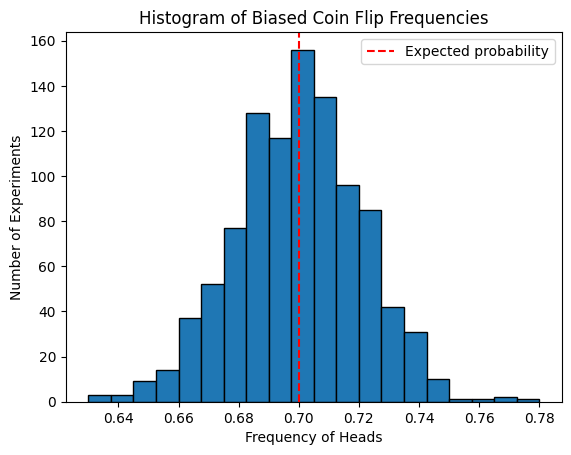

Average frequency: 69.98%
Central 95% of results: 65.60% - 73.80%


In [9]:

np.random.seed(0)

# Simulate 1,000 experiments of 500 biased coin flips each
frequency_array = np.random.binomial(500, 0.7, 1000) / 500

# Create a histogram
plt.hist(frequency_array, bins=20, edgecolor="black")
plt.axvline(0.7, color="red", linestyle="--", label="Expected probability")
plt.xlabel("Frequency of Heads")
plt.ylabel("Number of Experiments")
plt.title("Histogram of Biased Coin Flip Frequencies")
plt.legend()
plt.show()

# Calculate an interval containing about 95% of results
lower = np.percentile(frequency_array, 2.5)
upper = np.percentile(frequency_array, 97.5)

print(f"Average frequency: {frequency_array.mean() * 100:.2f}%")
print(f"Central 95% of results: {lower * 100:.2f}% - {upper * 100:.2f}%")


**Observation:** Most of the simulated frequencies are close to 70%. The histogram shows how the results are distributed, while the 95% interval describes the range containing most of our simulated outcomes.

### 7. What is the central limit theorem?

The **central limit theorem** states that the distribution of sample means approaches a normal (bell-shaped) distribution as the sample size becomes sufficiently large, under suitable conditions.

This explains why repeated coin-flip percentages tend to cluster around the expected probability.

### 8. Can we compute a histogram's parameters without plotting it?

Yes. NumPy's `np.histogram()` calculates bin counts and bin boundaries without drawing a graph.

In [10]:
# Calculate histogram information without drawing a graph
counts, bin_edges = np.histogram(frequency_array, bins=10)

print("Number of observations in each bin:")
print(counts)

print("\nBoundaries of each bin:")
print(bin_edges)

print(f"\nTotal observations: {counts.sum()}")

Number of observations in each bin:
[  6  23  89 205 273 231 127  41   2   3]

Boundaries of each bin:
[0.63  0.645 0.66  0.675 0.69  0.705 0.72  0.735 0.75  0.765 0.78 ]

Total observations: 1000


**Observation:** NumPy calculates how many values fall into each bin without creating a graph. This is useful when we only need the numerical histogram data.


## Part 3 — Connecting Simulations to Our Card Game

### 9. How is this relevant to our card game?

We can simulate thousands of shuffled decks, test different stopping strategies, and calculate how often we win. Histograms and confidence intervals help us evaluate those results.

In [11]:

np.random.seed(0)

# Generate a deck containing an unknown number of red cards
total_cards = 52
red_card_count = np.random.randint(0, total_cards + 1)
black_card_count = total_cards - red_card_count

# Probability of drawing a red card
prob_red = red_card_count / total_cards

# Simulate seeing the first card after 50,000 reshuffles
num_shuffles = 50000
observed_red = np.random.binomial(num_shuffles, prob_red)

# Estimate how many red cards are in the deck
estimated_probability = observed_red / num_shuffles
estimated_red_cards = round(estimated_probability * total_cards)

print(f"Estimated red-card probability: {estimated_probability * 100:.2f}%")
print(f"Estimated number of red cards: {estimated_red_cards}")

# Check our estimate
print(f"Actual number of red cards: {red_card_count}")
print(f"Estimate correct: {estimated_red_cards == red_card_count}")


Estimated red-card probability: 84.63%
Estimated number of red cards: 44
Actual number of red cards: 44
Estimate correct: True


**Observation:** By repeatedly sampling the first card after reshuffling, we can estimate how many red cards are in the deck without counting every card individually.

### 10. How does the chapter propose we shuffle the cards?

We use **`np.random.permutation()`** to randomly rearrange a deck represented by 1s (red cards) and 0s (black cards).

### 11. Why do we switch to a 10-card deck?

A 52-card deck has too many possible arrangements to examine individually. A 10-card deck with five red and five black cards has only **252 unique color arrangements**, making exact probability calculations possible.

In [12]:
import itertools

np.random.seed(0)

# Create a 52-card deck
deck = [1] * 26 + [0] * 26

# Shuffle the full deck
shuffled_deck = np.random.permutation(deck)

print("Shuffled 52-card deck:")
print(shuffled_deck)

# Create a smaller 10-card deck
small_deck = [1] * 5 + [0] * 5

# Generate every unique arrangement
sample_space = set(itertools.permutations(small_deck))

print(f"\nUnique arrangements of a 10-card deck: {len(sample_space)}")
print(f"Expected number of arrangements: 252")

Shuffled 52-card deck:
[0 0 1 0 1 0 0 0 0 1 1 1 0 0 0 0 1 1 0 0 1 0 0 1 1 0 1 0 1 0 1 1 1 1 0 0 1
 1 0 1 1 1 0 1 1 1 0 0 1 1 0 0]

Unique arrangements of a 10-card deck: 252
Expected number of arrangements: 252


**Observation:** The full deck can be shuffled using NumPy, but the smaller 10-card deck allows us to generate all 252 possible color arrangements. This makes exact probability analysis easier.


---

## Chapter 3 — Conclusion

Chapter 3 taught us how to simulate random events using NumPy and analyze results with histograms and confidence intervals.

We learned how simulations help estimate probabilities and how using a smaller deck makes exact analysis easier.

**These tools prepare us to test our card game strategies in Chapter 4.**